In [2]:
from pathlib import Path

# Identify project directory
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Load processed dataset
PROCESSED_DATA_PATH = (
    PROJECT_DIR / "data" / "processed" / "cleaned_training_text.txt"
)

with open(PROCESSED_DATA_PATH, "r", encoding="utf-8") as file:
    cleaned_text = file.read()

print("Processed dataset loaded successfully!")
print("Dataset path:", PROCESSED_DATA_PATH)
print("Data type:", type(cleaned_text))
print("Total characters:", len(cleaned_text))
print("Total words:", len(cleaned_text.split()))

print("\nFirst 300 characters:")
print(cleaned_text[:300])

Processed dataset loaded successfully!
Dataset path: /Users/vijaypatidar/vijay/Anshul/NextWord pred/data/processed/cleaned_training_text.txt
Data type: <class 'str'>
Total characters: 61552
Total words: 8520

First 300 characters:
artificial intelligence

artificial intelligence is a field of computer science that builds systems capable of performing tasks associated with human intelligence. these tasks include understanding language, recognizing images, planning actions, solving problems, and learning from experience. an ai 


In [3]:
# Basic word-level tokenization

tokens = cleaned_text.split()

print("First 20 tokens:")
print(tokens[:20])

print("\nTotal tokens:", len(tokens))

print("\nFirst 10 token types:")
print([type(token) for token in tokens[:10]])

print("\nTotal unique words:", len(set(tokens)))


First 20 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human']

Total tokens: 8520

First 10 token types:
[<class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>, <class 'str'>]

Total unique words: 2610


In [4]:
from collections import Counter

# Calculate word frequencies
word_counts = Counter(tokens)

# Create vocabulary
vocabulary = list(word_counts.keys())
vocabulary

print("Vocabulary created successfully!")

print("\nTotal vocabulary words:", len(vocabulary))

print("\nFirst 20 vocabulary words:")
print(vocabulary[:20])

print("\nTop 15 most frequent words:")
for word, count in word_counts.most_common(15):
    print(f"{word:20} : {count}")

Vocabulary created successfully!

Total vocabulary words: 2610

First 20 vocabulary words:
['artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence.', 'these', 'include']

Top 15 most frequent words:
and                  : 321
a                    : 299
the                  : 256
should               : 149
can                  : 140
to                   : 120
model                : 96
be                   : 90
is                   : 67
of                   : 67
an                   : 67
data                 : 67
or                   : 61
that                 : 60
in                   : 58


In [5]:
# Create word-to-index mapping
word_to_index = {
    word: index
    for index, word in enumerate(vocabulary, start=1)
}
# Create reverse index-to-word mapping
index_to_word = {
    index: word
    for word, index in word_to_index.items()
}


print("Word-to-index mapping created!")
print("\nFirst 15 mappings:")

for word, index in list(word_to_index.items())[:15]:
    print(f"{word:20} -> {index}")

print("\nTotal word mappings:", len(word_to_index))
print("Total index mappings:", len(index_to_word))



Word-to-index mapping created!

First 15 mappings:
artificial           -> 1
intelligence         -> 2
is                   -> 3
a                    -> 4
field                -> 5
of                   -> 6
computer             -> 7
science              -> 8
that                 -> 9
builds               -> 10
systems              -> 11
capable              -> 12
performing           -> 13
tasks                -> 14
associated           -> 15

Total word mappings: 2610
Total index mappings: 2610


In [6]:
# Test sentence
sample_sentence = "artificial intelligence is a field"

# Convert words into numerical IDs
sample_ids = [
    word_to_index[word]
    for word in sample_sentence.split()
]

# Convert numerical IDs back into words
reconstructed_words = [
    index_to_word[index]
    for index in sample_ids
]


reconstructed_sentence = " ".join(reconstructed_words)

print("Original sentence:")
print(sample_sentence)

print("\nNumerical representation:")
print(sample_ids)

print("\nReconstructed sentence:")
print(reconstructed_sentence)

print("\nConversion successful:",
      sample_sentence == reconstructed_sentence)

Original sentence:
artificial intelligence is a field

Numerical representation:
[1, 2, 3, 4, 5]

Reconstructed sentence:
artificial intelligence is a field

Conversion successful: True


In [7]:
# Reserve special token IDs
PAD_TOKEN = "<PAD>"
OOV_TOKEN = "<OOV>"

# Create updated vocabulary with special tokens
updated_word_to_index = {
    PAD_TOKEN: 0,
    OOV_TOKEN: 1
}

# Assign actual words starting from index 2
for word in vocabulary:
    updated_word_to_index[word] = len(updated_word_to_index)

# Reverse mapping
updated_index_to_word = {
    index: word
    for word, index in updated_word_to_index.items()
}

updated_index_to_word

{0: '<PAD>',
 1: '<OOV>',
 2: 'artificial',
 3: 'intelligence',
 4: 'is',
 5: 'a',
 6: 'field',
 7: 'of',
 8: 'computer',
 9: 'science',
 10: 'that',
 11: 'builds',
 12: 'systems',
 13: 'capable',
 14: 'performing',
 15: 'tasks',
 16: 'associated',
 17: 'with',
 18: 'human',
 19: 'intelligence.',
 20: 'these',
 21: 'include',
 22: 'understanding',
 23: 'language,',
 24: 'recognizing',
 25: 'images,',
 26: 'planning',
 27: 'actions,',
 28: 'solving',
 29: 'problems,',
 30: 'and',
 31: 'learning',
 32: 'from',
 33: 'experience.',
 34: 'an',
 35: 'ai',
 36: 'system',
 37: 'uses',
 38: 'data,',
 39: 'algorithms,',
 40: 'computing',
 41: 'resources',
 42: 'to',
 43: 'produce',
 44: 'useful',
 45: 'outputs.',
 46: 'the',
 47: 'quality',
 48: 'depends',
 49: 'on',
 50: 'problem',
 51: 'definition,',
 52: 'data',
 53: 'used,',
 54: 'model',
 55: 'architecture,',
 56: 'way',
 57: 'evaluated.',
 58: 'not',
 59: 'single',
 60: 'algorithm.',
 61: 'it',
 62: 'includes',
 63: 'search,',
 64: 'planni

In [8]:
# Test sentence containing one unknown word
sample_sentence = "artificial intelligence chatbotxyz"

# Convert words into IDs, using OOV ID for unknown words
sample_ids = [
    updated_word_to_index.get(word, updated_word_to_index[OOV_TOKEN])
    for word in sample_sentence.split()
]

print("Input sentence:")
print(sample_sentence)

print("\nNumerical representation:")
print(sample_ids)

print("\nDecoded tokens:")
print([
    updated_index_to_word[index]
    for index in sample_ids
])

print("\nUnknown word mapped to OOV:",
      sample_ids[-1] == updated_word_to_index[OOV_TOKEN])

Input sentence:
artificial intelligence chatbotxyz

Numerical representation:
[2, 3, 1]

Decoded tokens:
['artificial', 'intelligence', '<OOV>']

Unknown word mapped to OOV: True


In [9]:
# Convert complete token sequence into numerical IDs
encoded_sequence = [
    updated_word_to_index.get(word, updated_word_to_index[OOV_TOKEN])
    for word in tokens
]

print("Complete text encoding successful!")

print("\nOriginal tokens (first 20):")
print(tokens[:20])

print("\nEncoded sequence (first 20):")
print(encoded_sequence[:20])

print("\nTotal encoded tokens:", len(encoded_sequence))

print("\nMinimum token ID:", min(encoded_sequence))
print("Maximum token ID:", max(encoded_sequence))

# Verify sequence length
print("\nSequence length verification:",
      len(encoded_sequence) == len(tokens))

Complete text encoding successful!

Original tokens (first 20):
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human']

Encoded sequence (first 20):
[2, 3, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 7, 14, 15, 16, 17, 18]

Total encoded tokens: 8520

Minimum token ID: 2
Maximum token ID: 2611

Sequence length verification: True


In [10]:
# Decode complete numerical sequence
decoded_tokens = [
    updated_index_to_word[token_id]
    for token_id in encoded_sequence
]

# Compare original and reconstructed tokens
print("Original token count:", len(tokens))
print("Decoded token count:", len(decoded_tokens))

print("\nOriginal first 20 tokens:")
print(tokens[:20])

print("\nDecoded first 20 tokens:")
print(decoded_tokens[:20])

print("\nComplete reconstruction successful:",
      tokens == decoded_tokens)

print("\nTotal mismatches:",
      sum(original != decoded
          for original, decoded in zip(tokens, decoded_tokens)))

Original token count: 8520
Decoded token count: 8520

Original first 20 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human']

Decoded first 20 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human']

Complete reconstruction successful: True

Total mismatches: 0


Vocabulary frequency analysis
-----------------------------------
Most frequent word count: 321
Least frequent word count: 1
Words appearing only once: 1513
Words appearing 5 times or less: 2356
Words appearing more than 10 times: 97


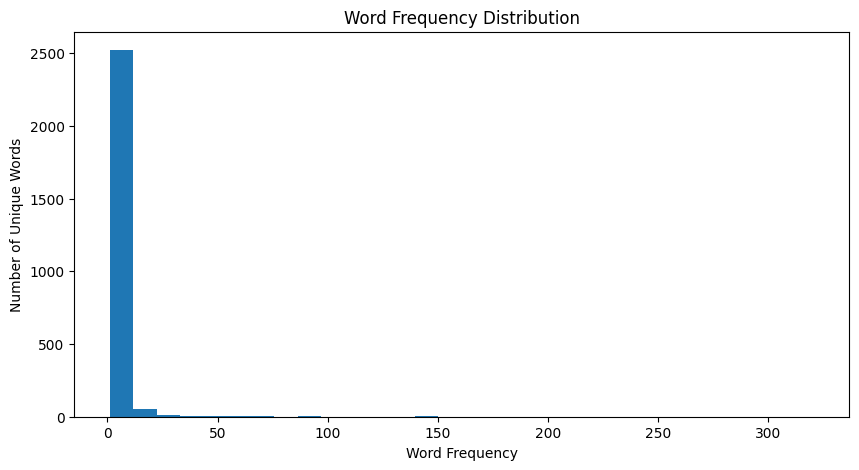

In [11]:
import matplotlib.pyplot as plt

# Get frequency of every vocabulary word
frequencies = list(word_counts.values())

# Calculate frequency statistics
print("Vocabulary frequency analysis")
print("-" * 35)

print("Most frequent word count:", max(frequencies))
print("Least frequent word count:", min(frequencies))

print("Words appearing only once:",
      sum(count == 1 for count in frequencies))

print("Words appearing 5 times or less:",
      sum(count <= 5 for count in frequencies))

print("Words appearing more than 10 times:",
      sum(count > 10 for count in frequencies))

# Plot frequency distribution
plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=30)
plt.title("Word Frequency Distribution")
plt.xlabel("Word Frequency")
plt.ylabel("Number of Unique Words")
plt.show()

In [12]:
# Identify rare words
rare_words = {
    word: count
    for word, count in word_counts.items()
    if count <= 2
}

# Display statistics
print("Rare word analysis")
print("-" * 35)

print("Words appearing once or twice:", len(rare_words))

print("\nFirst 30 rare words:")
for word, count in list(rare_words.items())[:30]:
    print(f"{word:25} : {count}")

# Percentage of vocabulary
rare_percentage = (len(rare_words) / len(vocabulary)) * 100

print("\nRare vocabulary percentage:",
      round(rare_percentage, 2), "%")

Rare word analysis
-----------------------------------
Words appearing once or twice: 1958

First 30 rare words:
field                     : 2
capable                   : 1
performing                : 1
associated                : 1
intelligence.             : 1
language,                 : 1
recognizing               : 1
images,                   : 1
planning                  : 2
actions,                  : 2
solving                   : 1
problems,                 : 1
experience.               : 1
algorithms,               : 1
computing                 : 2
outputs.                  : 2
definition,               : 1
used,                     : 1
way                       : 1
evaluated.                : 1
algorithm.                : 1
search,                   : 1
planning,                 : 2
symbolic                  : 1
reasoning,                : 1
representation,           : 1
processing.               : 2
others                    : 1
methods.                  : 1
example,         

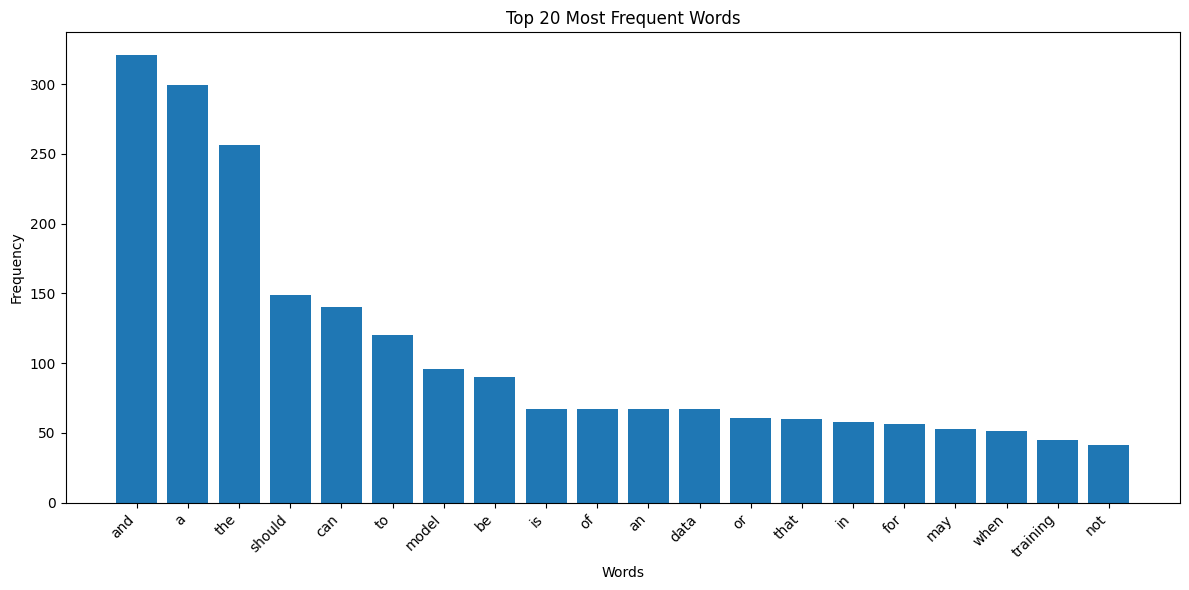

In [13]:
import matplotlib.pyplot as plt

# Get top 20 frequent words
top_20_words = word_counts.most_common(20)

words = [word for word, count in top_20_words]
counts = [count for word, count in top_20_words]

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(words, counts)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
import string

# Identify words ending with punctuation
punctuation_words = {
    word: count
    for word, count in word_counts.items()
    if word and word[-1] in string.punctuation
}

print("Punctuation fragmentation analysis")
print("-" * 40)

print("Total vocabulary words:", len(vocabulary))
print("Words ending with punctuation:", len(punctuation_words))

print("\nFirst 30 examples:")
for word, count in list(punctuation_words.items())[:30]:
    print(f"{word:25} : {count}")

percentage = len(punctuation_words) / len(vocabulary) * 100

print("\nPunctuation-related vocabulary percentage:",
      round(percentage, 2), "%")

Punctuation fragmentation analysis
----------------------------------------
Total vocabulary words: 2610
Words ending with punctuation: 792

First 30 examples:
intelligence.             : 1
language,                 : 1
images,                   : 1
actions,                  : 2
problems,                 : 1
experience.               : 1
data,                     : 4
algorithms,               : 1
outputs.                  : 2
definition,               : 1
used,                     : 1
architecture,             : 3
evaluated.                : 1
algorithm.                : 1
search,                   : 1
planning,                 : 2
reasoning,                : 1
learning,                 : 3
representation,           : 1
processing.               : 2
rules,                    : 4
examples.                 : 5
methods.                  : 1
example,                  : 1
question,                 : 1
documents,                : 1
allowed.                  : 1
useful,                   : 3


In [15]:
import re
from collections import Counter

# Separate words and punctuation into individual tokens
punctuation_aware_tokens = re.findall(
    r"\w+|[^\w\s]",
    cleaned_text.lower()
)

# Build experimental vocabulary
punctuation_aware_counts = Counter(punctuation_aware_tokens)

punctuation_aware_vocabulary = set(punctuation_aware_tokens)

print("Punctuation-aware tokenization")
print("-" * 40)

print("Original token count:", len(tokens))
print("New token count:", len(punctuation_aware_tokens))

print("Original vocabulary size:", len(vocabulary))
print("New vocabulary size:", len(punctuation_aware_vocabulary))

print("\nFirst 30 tokens:")
print(punctuation_aware_tokens[:30])

print("\nPunctuation examples:")
print([
    token for token in punctuation_aware_tokens[:50]
    if token in string.punctuation
])

Punctuation-aware tokenization
----------------------------------------
Original token count: 8520
New token count: 9882
Original vocabulary size: 2610
New vocabulary size: 2052

First 30 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence', '.', 'these', 'tasks', 'include', 'understanding', 'language', ',', 'recognizing', 'images']

Punctuation examples:
['.', ',', ',', ',', ',', '.', ',', ',']


In [16]:
# Analyze punctuation-aware vocabulary

experimental_frequencies = list(
    punctuation_aware_counts.values()
)

print("Experimental vocabulary analysis")
print("-" * 40)

print("Total unique tokens:",
      len(punctuation_aware_vocabulary))

print("Tokens appearing once:",
      sum(count == 1 for count in experimental_frequencies))

print("Tokens appearing once or twice:",
      sum(count <= 2 for count in experimental_frequencies))

print("Tokens appearing 5 times or less:",
      sum(count <= 5 for count in experimental_frequencies))

print("Tokens appearing more than 10 times:",
      sum(count > 10 for count in experimental_frequencies))

print("\nTop 20 frequent tokens:")

for token, count in punctuation_aware_counts.most_common(20):
    print(f"{token:20} : {count}")

print("\nPunctuation token frequencies:")

for punctuation in string.punctuation:
    if punctuation in punctuation_aware_counts:
        print(
            f"{punctuation:10} : "
            f"{punctuation_aware_counts[punctuation]}"
        )

Experimental vocabulary analysis
----------------------------------------
Total unique tokens: 2052
Tokens appearing once: 976
Tokens appearing once or twice: 1357
Tokens appearing 5 times or less: 1738
Tokens appearing more than 10 times: 129

Top 20 frequent tokens:
.                    : 625
,                    : 534
and                  : 321
a                    : 300
the                  : 256
should               : 149
can                  : 140
to                   : 124
model                : 113
-                    : 95
be                   : 90
data                 : 81
of                   : 69
is                   : 68
an                   : 67
or                   : 61
that                 : 60
training             : 60
in                   : 58
for                  : 56

Punctuation token frequencies:
"          : 2
'          : 3
,          : 534
-          : 95
.          : 625
/          : 1
:          : 2
;          : 1


In [17]:
# Final token sequence
final_tokens = punctuation_aware_tokens.copy()

# Final token frequencies
final_word_counts = Counter(final_tokens)

# Final vocabulary
final_vocabulary = list(final_word_counts.keys())

# Reserve special tokens
final_word_to_index = {
    "<PAD>": 0,
    "<OOV>": 1
}

# Assign IDs to actual tokens
for token in final_vocabulary:
    final_word_to_index[token] = len(final_word_to_index)

# Reverse mapping
final_index_to_word = {
    index: token
    for token, index in final_word_to_index.items()
}

print("Final tokenizer created!")
print("-" * 40)

print("Total tokens:", len(final_tokens))
print("Actual vocabulary size:", len(final_vocabulary))
print("Total vocabulary including special tokens:",
      len(final_word_to_index))

print("\nSpecial token IDs:")
print("<PAD>:", final_word_to_index["<PAD>"])
print("<OOV>:", final_word_to_index["<OOV>"])

print("\nFirst 15 mappings:")
for token, index in list(final_word_to_index.items())[:15]:
    print(f"{token:20} -> {index}")

Final tokenizer created!
----------------------------------------
Total tokens: 9882
Actual vocabulary size: 2052
Total vocabulary including special tokens: 2054

Special token IDs:
<PAD>: 0
<OOV>: 1

First 15 mappings:
<PAD>                -> 0
<OOV>                -> 1
artificial           -> 2
intelligence         -> 3
is                   -> 4
a                    -> 5
field                -> 6
of                   -> 7
computer             -> 8
science              -> 9
that                 -> 10
builds               -> 11
systems              -> 12
capable              -> 13
performing           -> 14


In [18]:
# Convert all tokens into numerical IDs
final_encoded_sequence = [
    final_word_to_index.get(
        token,
        final_word_to_index["<OOV>"]
    )
    for token in final_tokens
]

print("Final encoding completed!")
print("-" * 40)

print("Original tokens (first 30):")
print(final_tokens[:30])

print("\nEncoded IDs (first 30):")
print(final_encoded_sequence[:30])

print("\nTotal encoded tokens:",
      len(final_encoded_sequence))

print("Minimum token ID:",
      min(final_encoded_sequence))

print("Maximum token ID:",
      max(final_encoded_sequence))

print("\nSequence length verification:",
      len(final_tokens) == len(final_encoded_sequence))

Final encoding completed!
----------------------------------------
Original tokens (first 30):
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence', '.', 'these', 'tasks', 'include', 'understanding', 'language', ',', 'recognizing', 'images']

Encoded IDs (first 30):
[2, 3, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 7, 14, 15, 16, 17, 18, 3, 19, 20, 15, 21, 22, 23, 24, 25, 26]

Total encoded tokens: 9882
Minimum token ID: 2
Maximum token ID: 2053

Sequence length verification: True


In [19]:
# Decode numerical sequence
final_decoded_tokens = [
    final_index_to_word[token_id]
    for token_id in final_encoded_sequence
]

# Validate complete reconstruction
print("Final tokenizer validation")
print("-" * 40)

print("Original token count:", len(final_tokens))
print("Decoded token count:", len(final_decoded_tokens))

print("\nOriginal first 30 tokens:")
print(final_tokens[:30])

print("\nDecoded first 30 tokens:")
print(final_decoded_tokens[:30])

print("\nComplete reconstruction successful:",
      final_tokens == final_decoded_tokens)

print("\nTotal mismatches:",
      sum(
          original != decoded
          for original, decoded in zip(
              final_tokens,
              final_decoded_tokens
          )
      ))

Final tokenizer validation
----------------------------------------
Original token count: 9882
Decoded token count: 9882

Original first 30 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence', '.', 'these', 'tasks', 'include', 'understanding', 'language', ',', 'recognizing', 'images']

Decoded first 30 tokens:
['artificial', 'intelligence', 'artificial', 'intelligence', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'builds', 'systems', 'capable', 'of', 'performing', 'tasks', 'associated', 'with', 'human', 'intelligence', '.', 'these', 'tasks', 'include', 'understanding', 'language', ',', 'recognizing', 'images']

Complete reconstruction successful: True

Total mismatches: 0


In [20]:
import json
import numpy as np

# Create artifacts directory
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Save word-to-index mapping
with open(ARTIFACTS_DIR / "word_to_index.json", "w",
          encoding="utf-8") as file:
    json.dump(final_word_to_index, file, ensure_ascii=False, indent=4)

# Save index-to-word mapping
with open(ARTIFACTS_DIR / "index_to_word.json", "w",
          encoding="utf-8") as file:
    json.dump(
        {str(k): v for k, v in final_index_to_word.items()},
        file,
        ensure_ascii=False,
        indent=4
    )

# Save tokenizer configuration
tokenizer_config = {
    "tokenization_method": "punctuation_aware_word_level",
    "padding_token": "<PAD>",
    "padding_token_id": 0,
    "oov_token": "<OOV>",
    "oov_token_id": 1,
    "vocabulary_size": len(final_word_to_index),
    "actual_vocabulary_size": len(final_vocabulary),
    "total_tokens": len(final_tokens)
}

with open(ARTIFACTS_DIR / "tokenizer_config.json", "w",
          encoding="utf-8") as file:
    json.dump(tokenizer_config, file, indent=4)

# Save encoded sequence
np.save(
    ARTIFACTS_DIR / "encoded_sequence.npy",
    np.array(final_encoded_sequence, dtype=np.int32)
)

print("Tokenizer artifacts saved successfully!")

print("\nSaved files:")
for file_path in ARTIFACTS_DIR.iterdir():
    print(file_path.name, "|", file_path.stat().st_size, "bytes")

Tokenizer artifacts saved successfully!

Saved files:
encoded_sequence.npy | 39656 bytes
tokenizer_config.json | 258 bytes
word_to_index.json | 43146 bytes
index_to_word.json | 47254 bytes


In [21]:
import json
import numpy as np

# Load word-to-index mapping
with open(ARTIFACTS_DIR / "word_to_index.json", "r",
          encoding="utf-8") as file:
    loaded_word_to_index = json.load(file)

# Load index-to-word mapping
with open(ARTIFACTS_DIR / "index_to_word.json", "r",
          encoding="utf-8") as file:
    loaded_index_to_word = {
        int(k): v for k, v in json.load(file).items()
    }

# Load tokenizer configuration
with open(ARTIFACTS_DIR / "tokenizer_config.json", "r",
          encoding="utf-8") as file:
    loaded_tokenizer_config = json.load(file)

# Load encoded sequence
loaded_encoded_sequence = np.load(
    ARTIFACTS_DIR / "encoded_sequence.npy"
)

# Verify loaded artifacts
print("ARTIFACT LOADING VALIDATION")
print("-" * 40)

print("Word mapping size:", len(loaded_word_to_index))
print("Index mapping size:", len(loaded_index_to_word))
print("Encoded sequence length:", len(loaded_encoded_sequence))

print("\nSpecial tokens:")
print("PAD:", loaded_word_to_index["<PAD>"])
print("OOV:", loaded_word_to_index["<OOV>"])

print("\nConfiguration:")
print(loaded_tokenizer_config)

print("\nWord mapping matches:",
      loaded_word_to_index == final_word_to_index)

print("Index mapping matches:",
      loaded_index_to_word == final_index_to_word)

print("Encoded sequence matches:",
      np.array_equal(
          loaded_encoded_sequence,
          np.array(final_encoded_sequence, dtype=np.int32)
      ))

ARTIFACT LOADING VALIDATION
----------------------------------------
Word mapping size: 2054
Index mapping size: 2054
Encoded sequence length: 9882

Special tokens:
PAD: 0
OOV: 1

Configuration:
{'tokenization_method': 'punctuation_aware_word_level', 'padding_token': '<PAD>', 'padding_token_id': 0, 'oov_token': '<OOV>', 'oov_token_id': 1, 'vocabulary_size': 2054, 'actual_vocabulary_size': 2052, 'total_tokens': 9882}

Word mapping matches: True
Index mapping matches: True
Encoded sequence matches: True
